# Speed vs Accuracy: the Best Ball Speed When Speed Costs Accuracy

- This notebook makes the spread of the return grow with the ball speed, and asks
  which ball speed gives player 2 the most winners, for tennis and pickleball
  (#723)
- The pedagogical arc:
  - The spread model: 4 shapes of the factor that multiplies the spread
  - The best ball speed for each coefficient `a`, as a band of tied speeds
  - What the best speed is robust to, and which shape wins
  - Proposition 1 when the spread depends on the ball speed
  - The threshold $a^*$ above which hitting as hard as possible stops paying
  - A summary of what is robust to what

In [1]:
%load_ext autoreload
%autoreload 2

import logging

# Outcome: edited modules reload on the next run, and `logging` is imported.

In [2]:
import helpers.hnotebook as hnotebook

from research.Optimal_strategy_for_racket_sports.notebooks import (
    racket_sports_07_speed_vs_accuracy_utils as utils,
)

# Initialize notebook configuration and logging.
hnotebook.config_notebook()
_LOG = logging.getLogger(__name__)
utils.init_loggers(_LOG)

# Convert `display` into `print()` when running outside IPython.
try:
    from IPython.display import display
except ImportError:
    display = print

# Outcome: the utils are loaded as `utils`, and their logs print here.

/tmp/r/research/Optimal_strategy_for_racket_sports/notebooks/racket_sports_07_speed_vs_accuracy_utils.py:36: TqdmExperimentalWarning: Using `tqdm.autonotebook.tqdm` in notebook mode. Use `tqdm.tqdm` instead to force console mode (e.g. in jupyter console)
  from tqdm.autonotebook import tqdm


INFO  > /usr/local/lib/python3.12/site-packages/ipykernel_launcher.py -f /tmp/tmp0lxf3zig.json --HistoryManager.hist_file=:memory:


# Part 0: How Much to Run

## Cell 0.1: Reduced or Full Runs

- The reduced runs take about a minute and a half, on one core
  - Parts 1 to 4: 9 ball speeds that keep $v_0 / 2$, $v_0$, and $2 v_0$, the base
    at 3 values of `a`, every kind of variant at `a = 1`, and 2000 samples per
    target
  - Part 5: the 4 shapes on 5 ball speeds in steps of 0.25 of `a`, with seeds 2
    and 3 for the tennis maps, 280 maps
  - The cells of each map are the same as in the full runs, so a reduced result
    compares cell by cell with a full one
- The full runs take about 55 minutes, and give the numbers of the paper and of
  the threshold
  - Parts 1 to 4, about 2 minutes: 16 ball speeds, the base at 5 values of `a`,
    every variant at `a` = 0.5 and 1, and 5000 samples per target
  - Part 5, 15,232 maps: 8,576 for the sweeps on a fine grid of `a`, and 6,656
    for the tennis maps of the 4 shapes with seeds 2 to 5
  - Seed 1, so each map repeats exactly from its settings string
- The numbers quoted in the markdown of this notebook are from the full runs

In [3]:
# Set to `True` for the full runs used in the paper.
RUN_FULL_SIMS = False
config = utils.get_experiment_config(RUN_FULL_SIMS)
print("RUN_FULL_SIMS=", RUN_FULL_SIMS)
print("n_maps=", utils.count_maps(config))
# Outcome: the reduced configuration, unless `RUN_FULL_SIMS` is changed.

RUN_FULL_SIMS= False
n_maps= 198


# Part 1: The Spread Model

## Cell 1.1: The Shapes of the Factor

**Goal**
- See how each shape makes the spread grow with the ball speed

**Description**
- The spread at the ball speed $v_b$ is the spread at the reference speed $v_0$
  times a factor $f$, with $u = (v_b - v_0) / v_0$:
  - Linear, the base: $f = 1 + a u$
  - Knee: $f = 1 + a \max(0, u)$
  - Parabola: $f = 1 + a u^2$
  - One-sided parabola: $f = 1 + a \max(0, u)^2$
- $v_0$ is the default ball speed of notebook 05: 25 m/s in tennis, 12 m/s in
  pickleball, where the spread is the default $(0.5, 1.0)$ m
- The depth gets $a_y = a$ and the width $a_x = a / 2$, our assumption
  - Sudo et al. (2024) found the trade-off in the hitting direction only, which
    is mostly the depth
- The range $a \in [0, 1]$ is our assumption: no study gives a value
  - $a = 0$ is the model of notebooks 01 and 05, where the spread does not depend
    on the ball speed

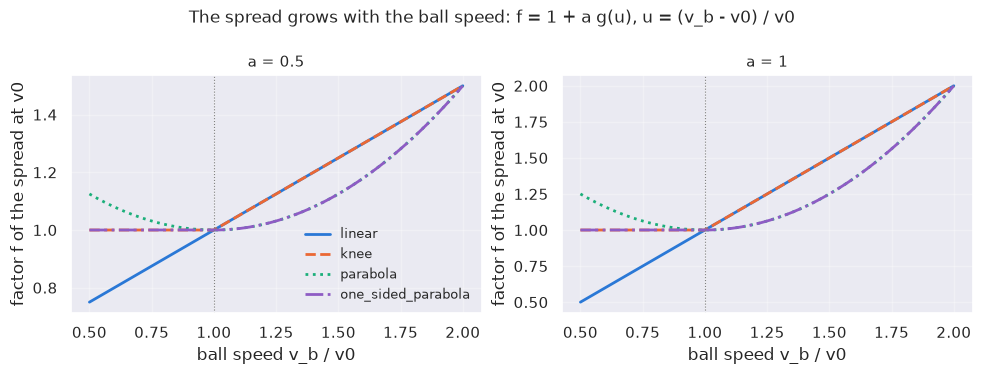

In [4]:
# Plot the factor of each shape, at 2 values of `a`.
_ = utils.plot_speed_factors([0.5, 1.0])
# Outcome: all the shapes give 1 at `v0` and `1 + a` at `2 v0`.

**Reading the output**
- Above $v_0$ the shapes differ only in how fast the spread grows
  - The parabolas grow more slowly: $1 + a / 4$ at $1.5 v_0$, against $1 + a / 2$
- Below $v_0$ they differ in kind
  - The linear shape makes a slower ball more accurate
  - The knee and the one-sided parabola keep the spread at $v_0$
  - The parabola makes a slower ball less accurate: $v_0$ is its most accurate
    speed

# Part 2: The Best Ball Speed

## Cell 2.1: Sweeps of the Ball Speed

**Goal**
- Find the ball speed with the highest $P(winner)$ when a faster ball is less
  accurate

**Description**
- The ball speed goes from $v_0 / 2$ to $2 v_0$: 12.5 to 50 m/s in tennis, 6 to
  24 m/s in pickleball
- The other settings are the defaults of notebook 05
  - The model keeps `std_x2`, `std_y2`, and `ball_speed` as 3 independent inputs:
    the builder only sets the 2 spreads from the ball speed, map by map
- Every map of a sweep uses the same seed, so a change between 2 speeds comes from
  the speed and its spread, and not from sampling noise
- The best speed is a band: every speed within 2 standard errors of the highest
  $P(winner)$, the rule of the best region
  - The star is the speed in the middle of the band

In [5]:
# Run the sweeps of every variant.
sweeps = utils.run_speed_sweeps(config)
print("sweeps.shape=", sweeps.shape)
# Outcome: one row per map, with its settings string and the builder inputs.

speed sweeps:   0%|          | 0/180 [00:00<?, ?it/s]

sweeps.shape= (180, 37)


In [6]:
# Find the best ball speed of each sweep.
best_speeds = utils.find_best_speeds(sweeps)
print("best_speeds.shape=", best_speeds.shape)
# Outcome: one row per sport, variant, and `a`.

best_speeds.shape= (20, 18)


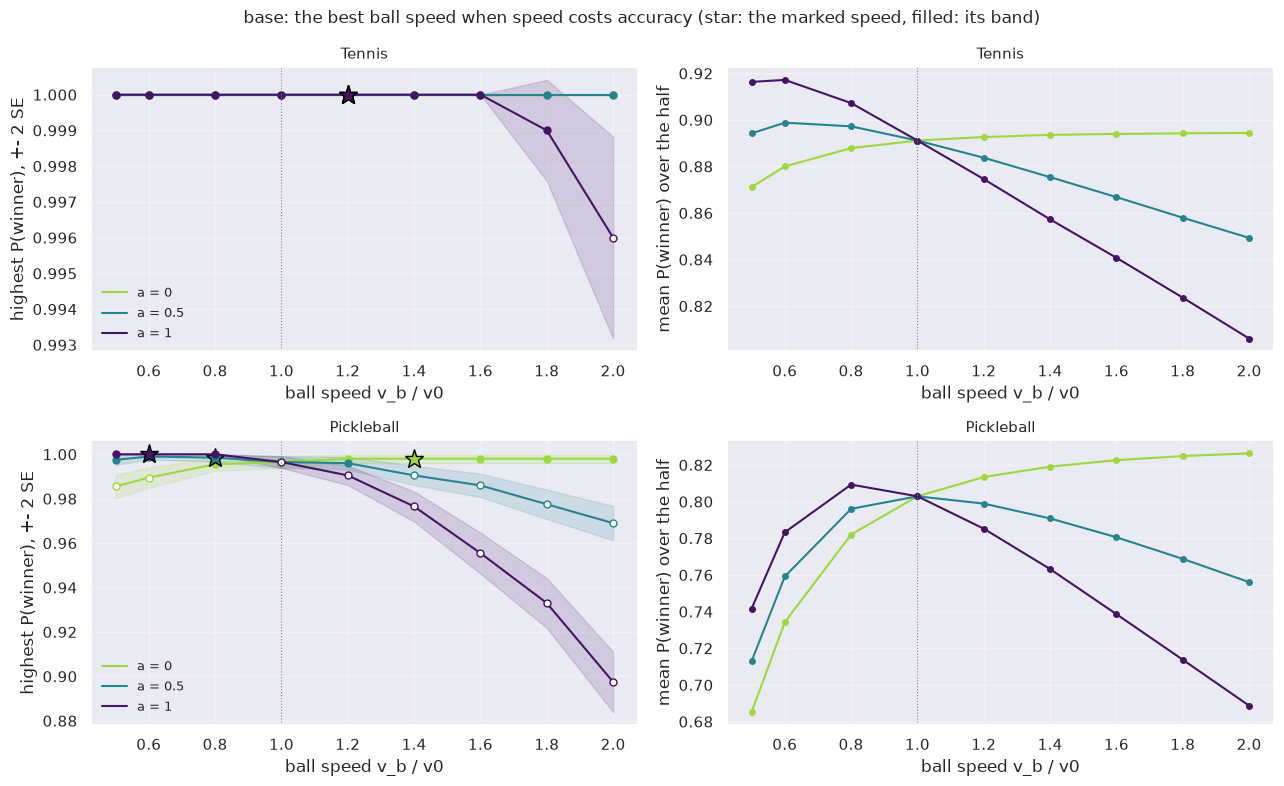

In [7]:
# Plot the base sweeps.
_ = utils.plot_speed_sweeps(sweeps, best_speeds, "base")
# Outcome: the larger `a`, the more the fast balls lose.

**Reading the output**
- Pickleball: the best ball speed falls as `a` grows
  - At `a = 0` the fastest balls tie at the top, as in notebook 05
  - At `a = 0.5` the band is $0.5$ to $1.0 \, v_0$, and at `a = 1` it is $0.5$ to
    $0.8 \, v_0$ (6 to 9.6 m/s), marked at $0.7 \, v_0$
  - The band reaches the slowest speed of the sweep: with the linear shape the
    best speed is at or below $v_0 / 2$
- Tennis: the highest $P(winner)$ is 1.000 at almost every speed, so it cannot
  rank the speeds, the same limit as in notebook 05
  - The mean over the half does: at `a = 1` it is highest at $0.6 \, v_0$ (15
    m/s), and the fastest ball loses 11.1 points on it

## Cell 2.2: Maps Along a Sweep

**Goal**
- See where on the court the winners go as the ball speeds up and spreads out

**Description**
- The maps of the base sweep at `a = 1`, at 4 ball speeds, all else at the
  defaults
  - The outline is the best region, and the star its middle

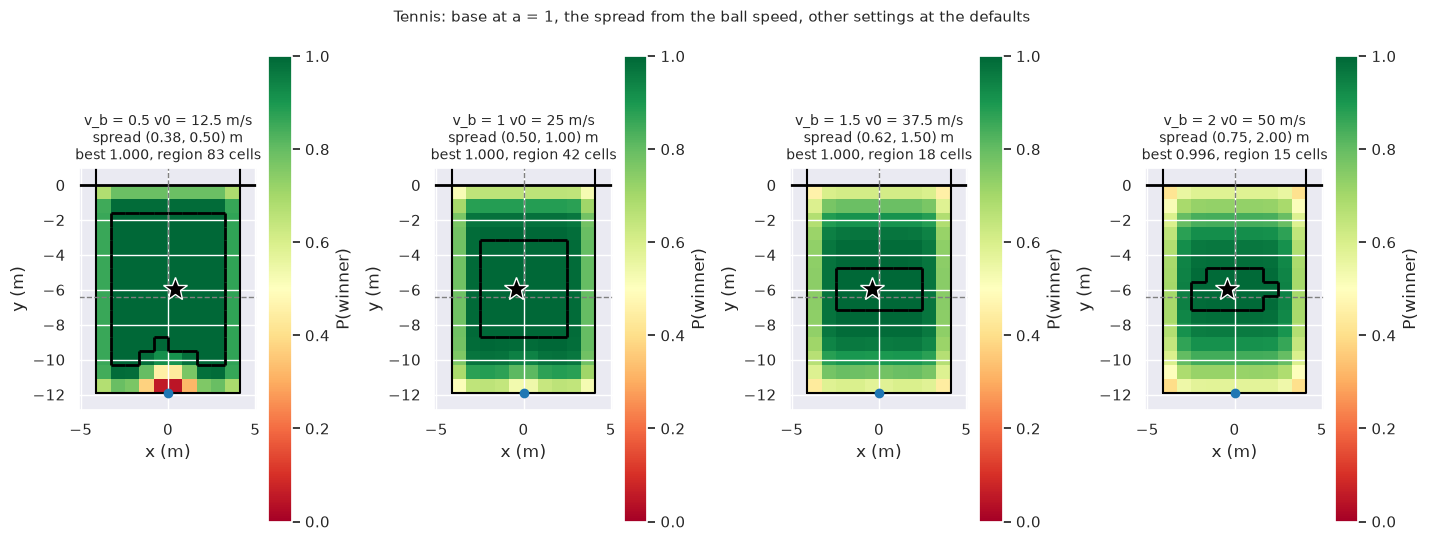

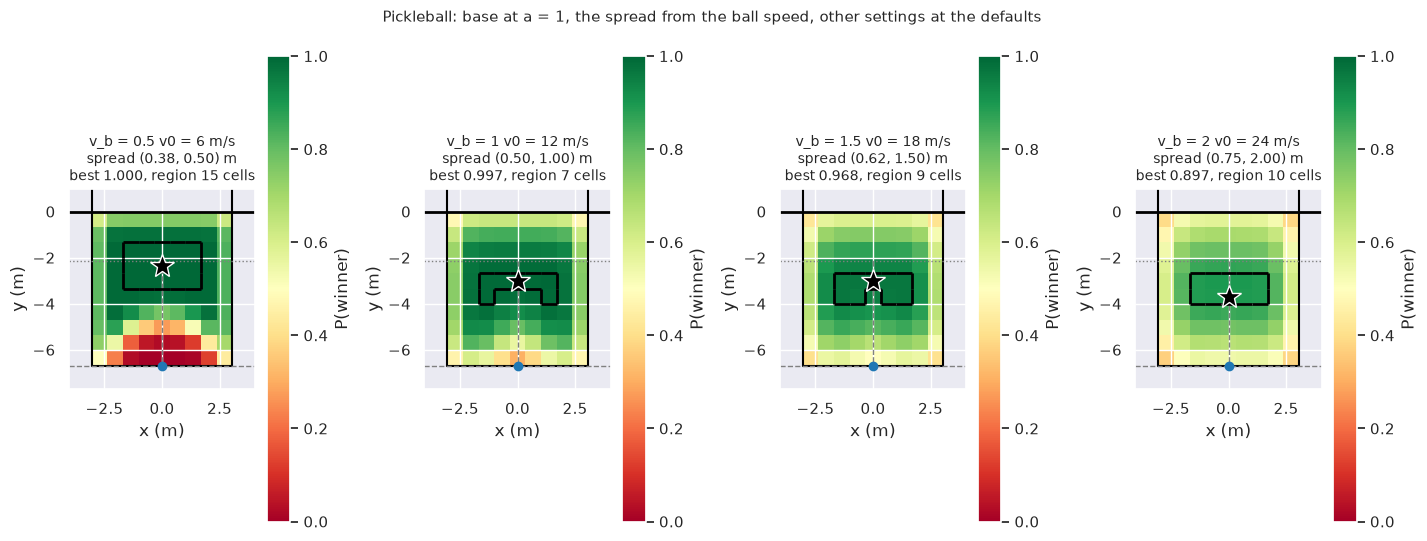

In [8]:
# Plot the maps along the base sweep at `a = 1`, for each sport.
for sport_name in config.sports:
    _ = utils.plot_sweep_maps(
        sport_name, "base", 1.0, [0.5, 1.0, 1.5, 2.0], config
    )
# Outcome: the spread grows with the ball speed, and the best region shrinks.

**Reading the output**
- At `a = 1` the spread goes from $(0.375, 0.5)$ m at $v_0 / 2$ to $(0.75, 2.0)$ m
  at $2 v_0$
- Pickleball: the highest $P(winner)$ falls from 1.000 at $v_0 / 2$ to 0.901 at
  $2 v_0$, since more returns land out
- Tennis: the best region shrinks from 70 to 8 of 150 cells, while its highest
  value stays near 1

## Cell 2.3: The Best Speed of Each Sweep

**Goal**
- Read the best ball speed of the base for each sport and `a`

**Description**
- `best_speed_ratio`: the marked speed, as $v_b / v_0$
- `band_low_ratio`, `band_high_ratio`: the ends of the band of tied speeds
  - `slowest_in_band`, `fastest_in_band`: the band reaches an end of the sweep, so
    the best speed may lie beyond it
- `fastest_loss_points`: what the fastest ball loses against the highest
  $P(winner)$, in percentage points
- `best_mean_speed_ratio`: the speed with the highest mean $P(winner)$ over the
  half, which does not saturate at 1

In [9]:
# Show the best speed of the base sweeps.
columns = ["sport", "a", "best_speed_ratio", "band_low_ratio", "band_high_ratio"]
columns += ["slowest_in_band", "fastest_in_band", "top_p_winner"]
columns += ["fastest_loss_points", "best_mean_speed_ratio"]
display(best_speeds.loc[best_speeds["variant"] == "base", columns].round(3))
# Outcome: one row per sport and `a`.

,sport,a,best_speed_ratio,band_low_ratio,band_high_ratio,slowest_in_band,fastest_in_band,top_p_winner,fastest_loss_points,best_mean_speed_ratio
0,Tennis,0.0,1.2,0.5,2.0,True,True,1.000,0.00,2.0
1,Tennis,0.5,1.2,0.5,2.0,True,True,1.000,0.00,0.6
2,Tennis,1.0,1.2,0.5,1.8,True,False,1.000,0.40,0.6
10,Pickleball,0.0,1.4,0.8,2.0,False,True,0.998,0.00,2.0
11,Pickleball,0.5,0.8,0.5,1.2,True,False,0.999,3.00,1.0
12,Pickleball,1.0,0.6,0.5,0.8,True,False,1.000,10.25,0.8


**Reading the output**
- At $a \ge 0.5$ the fastest ball loses 2.88 points in pickleball at `a = 0.5`
  and 9.88 at `a = 1`
- In tennis it loses at most 0.36 points on the highest cell, and 5.0 to 11.1
  points on the mean over the half

# Part 3: What the Best Speed Is Robust To

## Cell 3.1: The Best Speed Against `a`

**Goal**
- See how the best ball speed moves with `a`, for each shape

**Description**
- The line is the base, with its band shaded
- The markers are the other shapes at `a` = 0.5 and 1, with their bands as error
  bars, shifted a little in `a` so the bars do not hide each other

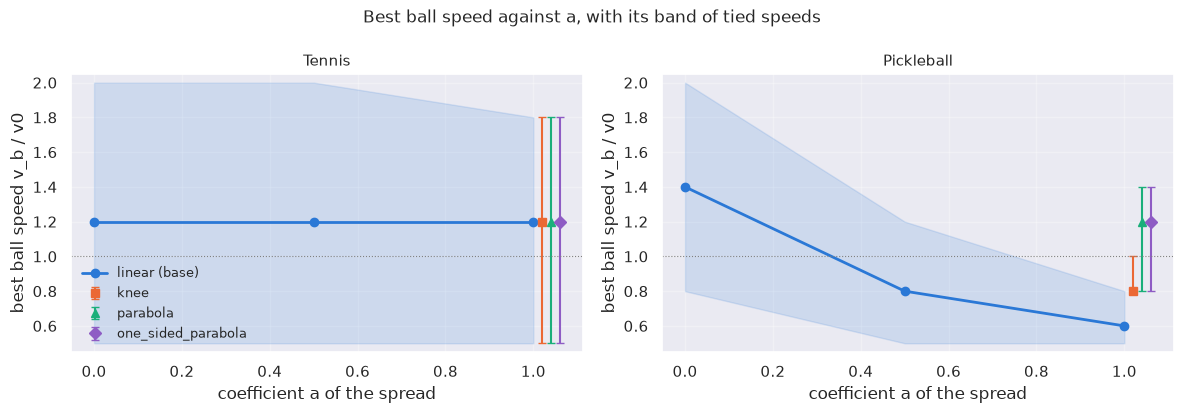

In [10]:
# Plot the best ball speed against `a`.
_ = utils.plot_best_speeds(best_speeds)
# Outcome: the paper's figure for Section VII-B.

**Reading the output**
- Pickleball: the linear base slides down to $v_0 / 2$, while the knee and the 2
  parabolas stay around $v_0$, marked at $1.0 \, v_0$ at `a = 1`
  - Only the linear shape makes a slower ball more accurate; with the others, a
    slower ball only gives player 1 more time
- Tennis: the 4 shapes give the same band, since the highest cell saturates

## Cell 3.2: One Variable at a Time

**Goal**
- Find what the best ball speed is robust to, and what it is not

**Description**
- Each variant changes one value of the base, at `a` = 0.5 and 1
  - Shapes: the knee, the parabola, and the one-sided parabola
  - Direction: $a_x = a_y$, a width as sensitive as the depth
  - Spread at $v_0$: halved to $(0.25, 0.5)$ m and doubled to $(1.0, 2.0)$ m
  - `v_p`: 1.9 m/s, the top of the split-step speeds in the paper's references,
    and 3.0 m/s, an assumption
  - Serve: the deep serve at the T, which helped player 1 most in notebook 05
  - Seed: 2, at `a = 1` only, to see the sampling noise
- The best speed is robust to a variant if its band shares at least one speed
  with the band of the base

In [11]:
# Compare the band of each variant with the band of the base.
robustness = utils.summarize_robustness(best_speeds)
display(robustness.round(3))
# Outcome: `overlaps` is True where the best speed is robust to the variant.

,sport,variant,a,base_band_low_ratio,base_band_high_ratio,band_low_ratio,band_high_ratio,n_shared,overlaps,d_best_speed_ratio,d_fastest_loss_points
0,Tennis,knee,1.0,0.5,1.8,0.5,1.8,8,True,0.0,0.00
1,Tennis,parabola,1.0,0.5,1.8,0.5,1.8,8,True,0.0,0.00
2,Tennis,one_sided_parabola,1.0,0.5,1.8,0.5,1.8,8,True,0.0,0.00
3,Tennis,a_x_eq_a_y,1.0,0.5,1.8,0.5,1.8,8,True,0.0,0.00
4,Tennis,std0_half,1.0,0.5,1.8,0.5,2.0,8,True,0.0,-0.40
5,Tennis,std0_double,1.0,0.5,1.8,0.5,0.8,3,True,-0.6,14.20
6,Tennis,v_p_3.0,1.0,0.5,1.8,0.5,1.8,8,True,0.0,0.00
7,Pickleball,knee,1.0,0.5,0.8,0.8,1.0,1,True,0.2,-0.35
8,Pickleball,parabola,1.0,0.5,0.8,0.8,1.4,1,True,0.6,-0.35
9,Pickleball,one_sided_parabola,1.0,0.5,0.8,0.8,1.4,1,True,0.6,-0.35


**Reading the output**
- Every band shares at least one speed with the base, but 2 kinds of variant
  move it
  - Shape: in pickleball at `a = 1` the knee and the parabolas share only
    $0.8 \, v_0$ with the base, and the marked speed moves from $0.7$ to
    $1.0 \, v_0$
  - Spread at $v_0$: doubled, it pulls the band to the slow end (only $v_0 / 2$
    in pickleball at `a = 1`) and the fastest ball loses 31.9 more points; halved,
    almost every speed ties
- $a_x = a_y$, `v_p`, the serve, and the seed move the marked speed by at most
  $0.1 \, v_0$
  - The exception is `v_p` = 3.0 m/s in pickleball at `a = 0.5`, which moves it up
    by $0.3 \, v_0$, while the 2 bands still share 4 speeds

## Cell 3.3: Which Shape Wins

**Goal**
- Compare the best speed and the loss of the fastest ball of the 4 shapes

In [12]:
# Show the best speed of the 4 shapes at `a` = 0.5 and 1.
shapes = ["base", "knee", "parabola", "one_sided_parabola"]
is_shape = best_speeds["variant"].isin(shapes) & (best_speeds["a"] > 0)
columns = ["sport", "variant", "a", "best_speed_ratio", "band_low_ratio"]
columns += ["band_high_ratio", "fastest_loss_points", "best_mean_speed_ratio"]
display(best_speeds.loc[is_shape, columns].round(3))
# Outcome: one row per sport, shape, and `a`.

,sport,variant,a,best_speed_ratio,band_low_ratio,band_high_ratio,fastest_loss_points,best_mean_speed_ratio
1,Tennis,base,0.5,1.2,0.5,2.0,0.00,0.6
2,Tennis,base,1.0,1.2,0.5,1.8,0.40,0.6
3,Tennis,knee,1.0,1.2,0.5,1.8,0.40,1.0
4,Tennis,parabola,1.0,1.2,0.5,1.8,0.40,1.0
5,Tennis,one_sided_parabola,1.0,1.2,0.5,1.8,0.40,1.0
11,Pickleball,base,0.5,0.8,0.5,1.2,3.00,1.0
12,Pickleball,base,1.0,0.6,0.5,0.8,10.25,0.8
13,Pickleball,knee,1.0,0.8,0.8,1.0,9.90,1.0
14,Pickleball,parabola,1.0,1.2,0.8,1.4,9.90,1.2
15,Pickleball,one_sided_parabola,1.0,1.2,0.8,1.4,9.90,1.2


**Reading the output**
- In tennis the 4 shapes tie
- In pickleball the shape decides the best speed below $v_0$: $0.7 \, v_0$ with the
  linear shape, $1.0 \, v_0$ with the others
- Every shape agrees that hitting much faster than $v_0$ does not pay at
  $a \ge 0.5$: the fastest ball loses 2.7 to 9.9 points in pickleball

# Part 4: Proposition 1 When Speed Costs Accuracy

## Cell 4.1: Scale the Speeds, With and Without $v_0$

**Goal**
- Check what Proposition 1 of notebook 05 becomes when the spread depends on the
  ball speed

**Description**
- With $t_r = 0$ and a spread that does not depend on the ball speed,
  $P(winner)$ depends on the 2 speeds only through $v_p / v_b$
- With the spread of this notebook the landing points depend on $v_b / v_0$ too
- The check takes the base at $v_b = v_0$ and $t_r = 0$, and compares every cell
  with 2 maps
  - `max_diff_speeds`: $v_p$ and $v_b$ doubled
  - `max_diff_speeds_and_v0`: $v_p$, $v_b$, and $v_0$ doubled
  - `mean_p_reached`: how much of the court player 1 reaches, so the rule is
    active

In [13]:
# Scale the speeds, then the speeds and `v0`, for each sport and `a`.
scaling_checks = utils.run_scaling_checks(config)
columns = ["sport", "a", "k", "max_diff_speeds", "max_diff_speeds_and_v0"]
columns += ["mean_p_reached"]
display(scaling_checks[columns])
# Outcome: `max_diff_speeds_and_v0` is 0 on every row, `max_diff_speeds` only at
# `a = 0`.

,sport,a,k,max_diff_speeds,max_diff_speeds_and_v0,mean_p_reached
0,Tennis,0.0,2.0,0.0000,0.0,0.013103
1,Tennis,0.5,2.0,0.1380,0.0,0.013103
2,Tennis,1.0,2.0,0.2280,0.0,0.013103
3,Pickleball,0.0,2.0,0.0000,0.0,0.069206
4,Pickleball,0.5,2.0,0.1800,0.0,0.069206
5,Pickleball,1.0,2.0,0.3105,0.0,0.069206


**Reading the output**
- At `a = 0` both scalings leave the maps unchanged: this is Proposition 1
- At `a > 0` doubling the 2 speeds changes the maps, since the doubled ball is at
  $2 v_0$, where the spread is $1 + a$ times larger
- Doubling $v_0$ with them leaves the maps unchanged, for every `a`
  - So with $t_r = 0$, $P(winner)$ depends on $v_p / v_b$ and on $v_b / v_0$

# Part 5: The Threshold of `a`

## Cell 5.1: What `a` Means

**Goal**
- Read the coefficient `a` as a number a player can picture

**Description**
- All 4 shapes give $f = 1 + a$ at $v_b = 2 v_0$
  - So doubling the ball speed widens the spread by $a \times 100\%$, whatever the
    shape
  - E.g., `a = 0.25`: the spread at $2 v_0$ is 25% wider than at $v_0$

In [14]:
# Compute the factor of each shape at `2 v0`, at `a = 0.25`.
for shape in utils.SPREAD_SHAPES:
    print(shape, "factor=", utils.compute_speed_factor(2.0, 1.0, 0.25, shape))
# Outcome: 1.25 for every shape.

linear factor= 1.25
knee factor= 1.25
parabola factor= 1.25
one_sided_parabola factor= 1.25


## Cell 5.2: Sweeps on a Fine Grid of `a`

**Goal**
- Find the smallest `a` at which hitting at $2 v_0$ stops being among the best
  speeds: the threshold $a^*$

**Description**
- `a` goes from 0 in steps of 0.025
  - Up to 0.5 for the knee and the 2 parabolas
  - Up to 1 for the linear shape, the base, since there $v_0$ itself leaves the
    band only above 0.5 in pickleball: the second threshold $a^{**}$
- The ball speeds, the samples, the seed, and the common random numbers are the
  ones of Part 2
- The robustness of $a^*$ changes one value of the linear base at a time, up to
  `a = 1`, in the full run only
  - The spread at $v_0$ halved and doubled, and `v_p` = 1.9 and 3.0 m/s
- The full run has 8,576 maps for the sweeps; the reduced run has 140, the 4
  shapes on 5 ball speeds in steps of 0.25 of `a`

In [15]:
# Run the sweeps of the threshold.
threshold_config = utils.get_threshold_config(RUN_FULL_SIMS)
print("n_maps=", utils.count_threshold_maps(threshold_config))
threshold_sweeps = utils.run_speed_sweeps(threshold_config.sweeps)
print("threshold_sweeps.shape=", threshold_sweeps.shape)
# Outcome: one row per map, as in Part 2.

n_maps= 280


speed sweeps:   0%|          | 0/140 [00:00<?, ?it/s]

threshold_sweeps.shape= (140, 37)


## Cell 5.3: The Standard Error of the Tennis Mean

**Goal**
- Get the standard error of the mean $P(winner)$ over the half, which ranks the
  tennis speeds

**Description**
- Pickleball ranks the speeds by the highest cell, with its own standard error, as
  in Part 2
- Tennis ranks them by the mean over the half, since its highest cell is 1.000 at
  almost every speed
  - The cells of a map share their draws, so their standard errors do not give
    the one of their mean
- Each tennis map of the 4 shapes runs again with seeds 2 to 5, all else equal:
  with seed 1 that is 5 independent estimates of its mean
  - The band uses their average, with their standard deviation over $\sqrt{5}$ as
    its standard error
  - The mean of the standard errors of the cells is shown next to it: it bounds
    the standard error of the mean from above
  - The variants of the base keep this bound in tennis
- The full run has 6,656 more tennis maps; the reduced run uses seeds 2 and 3,
  140 maps

In [16]:
# Run the tennis maps again with the other seeds.
threshold_sweeps = utils.add_seed_mean_se(threshold_sweeps, threshold_config)
is_tennis = threshold_sweeps["sport"] == "Tennis"
columns = ["mean_p_winner_seeds_se", "mean_p_winner_se"]
display(threshold_sweeps.loc[is_tennis, columns].describe().round(5))
# Outcome: the standard error from the seeds, and the bound of the cells.

seeds:   0%|          | 0/70 [00:00<?, ?it/s]

,mean_p_winner_seeds_se,mean_p_winner_se
count,70.00000,70.00000
mean,0.00047,0.00490
std,0.00015,0.00062
min,0.00011,0.00322
25%,0.00037,0.00464
50%,0.00042,0.00470
75%,0.00059,0.00496
max,0.00080,0.00729


**Reading the output**
- Over the 1,664 tennis maps of the 4 shapes, the standard error of the average of
  the 5 seeds has a median of 0.00034, and the bound of the cells 0.0030, 8.6
  times larger
  - One seed alone has a standard deviation 3.8 times smaller than the bound
    (2.4 to 5.6)
  - The average of the seeds moves the mean by 0.0004 from seed 1 (median)
- So the bound of the cells makes the tennis bands much wider, and $a^*$ larger

## Cell 5.4: The Band of the Best Speed Against `a`

**Goal**
- See where $2 v_0$ and $v_0$ leave the band of the best speed as `a` grows

**Description**
- The band of each sweep is every speed within 2 standard errors of the highest
  value, the rule of Part 2
- One panel per sport and shape
  - A filled square is a speed of the band at that `a`
  - The solid line is $a^*$, where $2 v_0$ leaves the band
  - The dashed line is $a^{**}$, where the whole band is slower than $v_0$

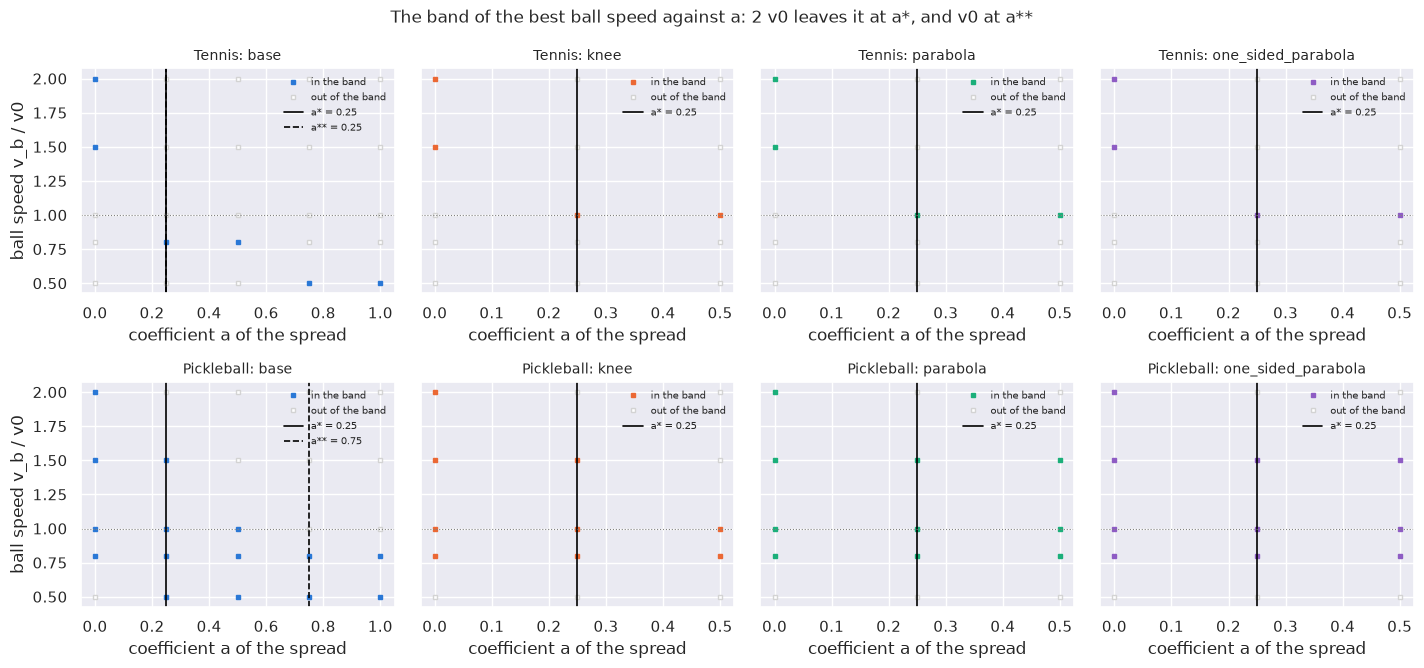

In [17]:
# Find the band of each sweep of the 4 shapes and the 2 thresholds, with the
# seeds in tennis.
shapes = list(threshold_config.seed_variants)
is_shape = threshold_sweeps["variant"].isin(shapes)
threshold_bands = utils.find_threshold_bands(threshold_sweeps[is_shape], "seeds")
thresholds_seeds = utils.find_speed_thresholds(threshold_bands)
_ = utils.plot_threshold_bands(threshold_bands, thresholds_seeds, shapes)
# Outcome: the band shrinks toward the slow speeds as `a` grows.

**Reading the output**
- $2 v_0$ leaves the band early, but the band shrinks gradually: at $a^*$ it still
  reaches 1.6 to 1.9 $v_0$
- Pickleball: the band of the linear shape goes from 0.7 to 1.9 $v_0$ at $a^*$ to
  0.5 to 1.0 $v_0$ at `a = 0.5`
  - The knee and the parabolas keep 0.8 $v_0$ as the slow end, and come down to
    1.2 and 1.5 $v_0$ at `a = 0.5`
- Tennis, with the seeds: the bands are narrower
  - At `a = 0.5` the knee is 1.0 $v_0$ alone, the parabolas 1.0 to 1.2 $v_0$, and
    the linear shape 0.6 to 0.7 $v_0$

## Cell 5.5: $a^*$ and $a^{**}$ of Each Shape

**Goal**
- Read the 2 thresholds of each sport and shape

**Description**
- `a_star`: the first `a` of the grid at which $2 v_0$ is out of the band
  - The true threshold is between `a_star_prev` and `a_star`
  - `fastest_reenters`: $2 v_0$ is in the band again at a larger `a`
  - `band_low_ratio_at_a_star`, `band_high_ratio_at_a_star`: the band at $a^*$
- `a_star_star`: the first `a` at which the whole band is slower than $v_0$
- `a_star_cells`, `a_star_star_cells`: the same with the bound of the cells in
  tennis; in pickleball they are the same
- NaN: the threshold is not reached up to `a_max`

In [18]:
# Put the thresholds of the 2 standard errors side by side.
threshold_bands_cells = utils.find_threshold_bands(threshold_sweeps, "cells")
thresholds_cells = utils.find_speed_thresholds(threshold_bands_cells)
is_shape = thresholds_cells["variant"].isin(shapes)
thresholds = utils.compare_tennis_se(
    thresholds_seeds, thresholds_cells[is_shape]
)
columns = ["sport", "variant", "a_max", "a_star_prev", "a_star", "a_star_cells"]
columns += ["fastest_reenters", "band_low_ratio_at_a_star"]
columns += ["band_high_ratio_at_a_star", "a_star_star", "a_star_star_cells"]
display(thresholds[columns])
# Outcome: one row per sport and shape.

,sport,variant,a_max,a_star_prev,a_star,a_star_cells,fastest_reenters,band_low_ratio_at_a_star,band_high_ratio_at_a_star,a_star_star,a_star_star_cells
0,Tennis,base,1.0,0.0,0.25,0.25,False,0.8,0.8,0.25,0.75
1,Tennis,knee,0.5,0.0,0.25,0.25,False,1.0,1.0,NaN,NaN
2,Tennis,parabola,0.5,0.0,0.25,0.25,False,1.0,1.0,NaN,NaN
3,Tennis,one_sided_parabola,0.5,0.0,0.25,0.25,False,1.0,1.0,NaN,NaN
4,Pickleball,base,1.0,0.0,0.25,0.25,False,0.5,1.5,0.75,0.75
5,Pickleball,knee,0.5,0.0,0.25,0.25,False,0.8,1.5,NaN,NaN
6,Pickleball,parabola,0.5,0.0,0.25,0.25,False,0.8,1.5,NaN,NaN
7,Pickleball,one_sided_parabola,0.5,0.0,0.25,0.25,False,0.8,1.5,NaN,NaN


**Reading the output**
- Pickleball: $a^* = 0.175$ for the linear shape and the 2 parabolas, and 0.2 for
  the knee
  - At $a^*$ the fastest ball loses 0.26 to 0.38 points of the highest
    $P(winner)$
- Tennis: $a^*$ depends on the standard error of the mean
  - With the seeds: 0.05 for the linear shape and the knee, 0.025 for the
    parabolas
  - With the bound of the cells: 0.15 and 0.125
- $a^{**}$ exists only for the linear shape: 0.6 in pickleball, and in tennis 0.25
  with the seeds and 0.525 with the bound
- No sweep has $2 v_0$ back in the band after $a^*$

## Cell 5.6: What $a^*$ Is Robust To

**Goal**
- See how much $a^*$ moves when one value of the linear base changes

**Description**
- The base, then the spread at $v_0$ halved and doubled, and `v_p` = 1.9 and 3.0
  m/s, each on the grid up to `a = 1`
  - Only the full run has the variants
- Tennis uses the bound of the cells here, for the base too, so that the rows
  compare

In [19]:
# Show the thresholds of the base and of its variants, with the bound of the
# cells in tennis.
variants = ["base", "std0_half", "std0_double", "v_p_1.9", "v_p_3.0"]
columns = ["sport", "variant", "tennis_se", "a_max", "a_star_prev", "a_star"]
columns += ["band_low_ratio_at_a_star", "band_high_ratio_at_a_star"]
columns += ["a_star_star"]
display(
    thresholds_cells.loc[thresholds_cells["variant"].isin(variants), columns]
)
# Outcome: one row per sport and variant.

,sport,variant,tennis_se,a_max,a_star_prev,a_star,band_low_ratio_at_a_star,band_high_ratio_at_a_star,a_star_star
0,Tennis,base,cells,1.0,0.0,0.25,0.5,1.5,0.75
4,Pickleball,base,cells,1.0,0.0,0.25,0.5,1.5,0.75


**Reading the output**
- The spread at $v_0$ matters most
  - Halved, it moves $a^*$ from 0.175 to 0.825 in pickleball, and from 0.15 to
    0.175 in tennis
  - Doubled, it lowers $a^*$ to 0.125 in both sports
- `v_p` = 1.9 m/s moves $a^*$ by at most 0.025
- `v_p` = 3.0 m/s raises it to 0.275 in pickleball and 0.225 in tennis: a faster
  server makes speed worth more

## Cell 5.7: The Conditional Claim

- Since `a` is unknown, the result is a claim that holds for any `a`, with no jump
  at $a^*$
- Draft for the abstract
  > Since how much accuracy a faster ball costs is unknown, we state the speed
  > result as a threshold: if doubling the ball speed widens the landing spread
  > by less than about 15 to 20% in pickleball (2.5 to 15% in tennis, depending
  > on the error estimate), the fastest ball stays among the best speeds; beyond
  > that, the best speeds come down gradually toward the base speed.
- Draft for Section VII-B
  > **A threshold on the cost of speed.** Since $a$ is unknown, we report $a^*$,
  > the smallest $a$ at which the fastest ball, $2 v_0$, leaves the band of the
  > best speed, on a grid of $a$ in steps of 0.025 with the speeds, seeds, and
  > common random numbers above. All four shapes give $f = 1 + a$ at $2 v_0$, so
  > $a$ is the fraction by which doubling the ball speed widens the spread. In
  > pickleball, ranked by the highest cell, $a^*$ is 0.175 to 0.2 across the four
  > shapes. In tennis, ranked by the mean over the server's half, $a^*$ depends on
  > the standard error of that mean: 0.025 to 0.05 with five independent seeds,
  > and 0.125 to 0.15 with the mean of the standard errors of the cells, an upper
  > bound about 9 times larger. So if doubling the ball speed widens the spread
  > by less than about 15 to 20% in pickleball ($a < a^*$), the fastest ball stays
  > among the best speeds. There is no jump at $a^*$: the fastest ball loses only
  > 0.1 to 0.4 points there, and the band still reaches 1.6 to 1.9 $v_0$ (tennis
  > with the seeds). Beyond $a^*$ the fastest speeds drop out of the band
  > gradually: at $a = 0.5$ the band of the knee and the parabolas tops out at 1.5
  > $v_0$ or less in pickleball and 1.2 $v_0$ or less in tennis (seeds), while the
  > band of the linear shape falls below $v_0$ ($a^{**}$ = 0.6 in pickleball, 0.25
  > to 0.525 in tennis). The main
  > sensitivity is the spread at $v_0$: halved, it moves $a^*$ of pickleball from
  > 0.175 to 0.825; doubled, to 0.125. A faster server, $v_p = 3.0$ m/s, raises
  > $a^*$ to 0.275 in pickleball and 0.225 in tennis, while $v_p = 1.9$ m/s moves
  > it by at most 0.025 (the tennis variants use the bound of the cells).

# Part 6: Summary

## Cell 6.1: What Is Robust to What

- **Hitting much faster than $v_0$ does not pay once speed costs accuracy**
  - At $a \ge 0.5$ the fastest ball, $2 v_0$, loses 2.7 to 9.9 points of the
    highest $P(winner)$ in pickleball, for every shape
  - In tennis the highest cell saturates, and the fastest ball loses 4.3 to 11.1
    points of the mean $P(winner)$ over the half
- **The best speed is robust to** $a_x = a_y$, `v_p`, the serve, and the seed
- **The main uncertainties are the shape below $v_0$ and the spread at $v_0$**
  - With the linear shape the best pickleball speed is at or below $v_0 / 2$;
    with the knee and the parabolas it is about $v_0$
  - A doubled spread at $v_0$ pulls the best speed to the slow end
- With $t_r = 0$ the maps depend on $v_p / v_b$ and on $v_b / v_0$, so
  Proposition 1 needs a spread that does not depend on the ball speed
- **Hitting as hard as possible pays only while speed costs little accuracy**
  - If doubling the ball speed widens the spread by less than about 15 to 20% in
    pickleball ($a < a^*$), $2 v_0$ stays among the best speeds; in tennis $a^*$
    is 0.025 to 0.05 with the seeds and 0.125 to 0.15 with the bound of the cells
  - Beyond $a^*$ the fastest speeds drop out of the band gradually: at `a = 0.5`
    the band of the knee and the parabolas tops out at 1.5 $v_0$ or less
  - The spread at $v_0$ moves $a^*$ the most: 0.825 in pickleball when it is
    halved
- Caveats
  - `a`, its range, and $a_x = a / 2$ are assumptions, not measurements
  - The highest $P(winner)$ saturates at 1 in tennis
  - In tennis $a^*$ depends on the standard error of the mean over the half, an
    open question for GP

## Cell 6.2: Save the Data of the Paper's Figure

- The full runs write a small CSV file next to the paper's figures
  - `figures/make_figures.py` of the paper draws the figure of Section VII-B from
    it
- The reduced runs write nothing, so they never change the paper's data

In [20]:
# Save the data of the paper's figure, for the full runs only.
if RUN_FULL_SIMS:
    path = utils.save_paper_figure_data(best_speeds, utils.PAPER_FIGURES_DIR)
    print("path=", path)
# Outcome: nothing in the reduced runs.